# 02 — Error analysis (test set)

Builds on `scripts/evaluate.py` (`make evaluate`), which writes the predictions of all five models on the
169 test reviews, heuristic tags and the summary tables to `reports/evaluation/`. This notebook explores
where the models disagree, which kinds of reviews they get wrong, and what BERTić attends to (FR-16).
All numbers are computed here from those files.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, Markdown, display

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
pred = pd.read_csv("reports/evaluation/test_predictions.csv")
summary = pd.read_csv("reports/evaluation/summary.csv").set_index("key")
pairwise = pd.read_csv("reports/evaluation/pairwise.csv")
rates = pd.read_csv("reports/evaluation/error_rates_by_tag.csv")
review = pd.read_csv("reports/error_analysis/manual_review.csv")
test = pd.read_parquet("data/processed/test.parquet").set_index("id")
MODELS = list(summary.index)
NAMES = summary["name"].to_dict()
summary[["name", "macro_f1", "ci_low", "ci_high", "accuracy", "latency_ms_single", "size_mb"]]

,name,macro_f1,ci_low,ci_high,accuracy,latency_ms_single,size_mb
key,,,,,,,
logreg,TF-IDF + Logistic Regression,0.834,0.775,0.888,0.834,4.090,1.491
linear_svm,TF-IDF + Linear SVM,0.834,0.775,0.888,0.834,7.231,5.666
naive_bayes,TF-IDF + Complement NB,0.798,0.734,0.858,0.799,4.976,4.498
bilstm,BiLSTM,0.769,0.704,0.833,0.769,3.209,41.770
bertic,BERTić,0.917,0.874,0.958,0.917,99.235,443.236


## 1. Who is right where?
For every pair of models: on how many test reviews exactly one of them is right.

In [2]:
wrong = pd.DataFrame({m: pred[f"{m}_pred"] != pred["label"] for m in MODELS})
only = pd.DataFrame(
    {NAMES[b]: [int((~wrong[a] & wrong[b]).sum()) for a in MODELS] for b in MODELS},
    index=[NAMES[a] for a in MODELS],
)
display(
    Markdown("Rows: reviews where the **row** model is right and the **column** model is wrong.")
)
only

Rows: reviews where the **row** model is right and the **column** model is wrong.

,TF-IDF + Logistic Regression,TF-IDF + Linear SVM,TF-IDF + Complement NB,BiLSTM,BERTić
TF-IDF + Logistic Regression,0,1,13,25,10
TF-IDF + Linear SVM,1,0,12,24,10
TF-IDF + Complement NB,7,6,0,22,10
BiLSTM,14,13,17,0,6
BERTić,24,24,30,31,0


In [3]:
n_all_wrong = int(wrong.all(axis=1).sum())
n_all_right = int((~wrong).all(axis=1).sum())
bertic_rescues = int(
    (~wrong["bertic"] & wrong[["logreg", "linear_svm", "naive_bayes"]].all(axis=1)).sum()
)
display(
    Markdown(
        f"- All five models are right on **{n_all_right}** of {len(pred)} reviews and all wrong on **{n_all_wrong}**.\n"
        f"- BERTić is right on **{bertic_rescues}** reviews that all three TF-IDF models get wrong."
    )
)

- All five models are right on **105** of 169 reviews and all wrong on **2**.
- BERTić is right on **18** reviews that all three TF-IDF models get wrong.

## 2. Error rate by heuristic tag
Thresholds come from the training split (see `reports/comparison.md`). A ratio above 1 means the tag makes the model *more* error-prone than on untagged reviews.

In [4]:
ratio = rates.pivot_table(index="tag", columns="model", values="ratio", sort=False)
ratio = ratio[[NAMES[m] for m in MODELS]]
ratio.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=0, vmax=2.5)

model,TF-IDF + Logistic Regression,TF-IDF + Linear SVM,TF-IDF + Complement NB,BiLSTM,BERTić
tag,,,,,
negation_dense,0.31,0.31,0.53,1.19,1.08
contrast_dense,0.57,0.57,0.89,1.19,0.94
questions,2.25,2.25,2.05,0.78,2.60
exclamations,1.10,0.93,1.62,0.60,1.29
short,1.17,1.17,0.76,0.53,0.80
long,0.64,0.64,0.90,2.51,1.63
contradicting_cues,4.26,4.26,2.92,1.45,2.05


## 3. Manual review of misclassified reviews
Each review was read and assigned one or more categories (`reports/error_analysis/manual_review.csv`).

In [5]:
long = review.assign(category=review["categories"].str.split(";")).explode("category")
merged = long.merge(pred, on="id")
counts = pd.DataFrame(
    {
        NAMES[m]: merged.groupby("category").apply(
            lambda g, m=m: int((g[f"{m}_pred"] != g["label"]).sum()), include_groups=False
        )
        for m in MODELS
    }
)
counts.insert(0, "reviews", long["category"].value_counts())
counts.sort_values("reviews", ascending=False)

,reviews,TF-IDF + Logistic Regression,TF-IDF + Linear SVM,TF-IDF + Complement NB,BiLSTM,BERTić
category,,,,,,
mixed_sentiment,21,15,16,15,14,5
negation,10,6,6,7,5,3
irony,9,7,8,9,5,1
slang,8,7,7,6,5,2
plot_summary,6,4,4,3,4,2
label_ambiguous,5,4,4,4,3,2
rare_vocabulary,5,2,2,3,4,2
verdict_truncated,1,0,0,1,1,0


In [6]:
top = counts.sort_values("reviews", ascending=False).index[0]
share_classical = counts.loc[top, NAMES["logreg"]] / counts.loc[top, "reviews"]
share_bertic = counts.loc[top, NAMES["bertic"]] / counts.loc[top, "reviews"]
irony = counts.loc["irony"] if "irony" in counts.index else None
lines = [
    f"- The most frequent category is **{top}** ({counts.loc[top, 'reviews']} of {len(review)} reviewed errors): "
    f"TF-IDF + LR fails on {share_classical:.0%} of them, BERTić on {share_bertic:.0%}."
]
if irony is not None:
    lines.append(
        f"- **Irony**: of {irony['reviews']} ironic reviews, TF-IDF + LR misclassifies {irony[NAMES['logreg']]}, "
        f"BERTić {irony[NAMES['bertic']]}."
    )
display(Markdown("\n".join(lines)))

- The most frequent category is **mixed_sentiment** (21 of 40 reviewed errors): TF-IDF + LR fails on 71% of them, BERTić on 24%.
- **Irony**: of 9 ironic reviews, TF-IDF + LR misclassifies 7, BERTić 1.

## 4. Illustrative cases
One review per pattern, with every model's probability for *positive*.

In [7]:
cases = {
    "Mixed sentiment (praise for the hype, verdict at the end)": 1186,
    "Irony / affectionate insults": 830,
    "Understated negation": 1610,
}
for title, rid in cases.items():
    row = pred.set_index("id").loc[rid]
    probs = " · ".join(f"{NAMES[m]}: {row[f'{m}_p_positive']:.2f}" for m in MODELS)
    note = review.set_index("id").loc[rid, "notes"]
    text = test.loc[rid, "text"]
    display(
        Markdown(
            f"**{title}** — id {rid}, gold *{row['label']}*\n\n"
            f"p(positive): {probs}\n\n> {text[:300]} […] {text[-300:]}\n\n*Note:* {note}"
        )
    )

**Mixed sentiment (praise for the hype, verdict at the end)** — id 1186, gold *negative*

p(positive): TF-IDF + Logistic Regression: 0.60 · TF-IDF + Linear SVM: 0.73 · TF-IDF + Complement NB: 0.67 · BiLSTM: 0.62 · BERTić: 0.06

> Osvetnici Jossa Whedona stigli su pred publiku pod štitom krupnih obećanja i glasnih kritičarskih hvalospeva u najavi, ali i pod teretom velikih očekivanja ponajpre od same, megalomanski postavljene premise o okupljanju svih ključnih Marvelovih junaka u jednom filmu, kao i zvučnih imena okupljenih n […] kao osnovnog i prirodnog habitata, ali za one iole zahtevnije i ne toliko sklone aboliciji favorita i kada ovako krupno (po)greše, ostaje tek loš film čiji će krajnje ishodište na prvom mestu ipak biti samo priče o zadivljujućoj statistici koja se tiče zarade na bioskopskim blagajnama širom planete.

*Note:* Opening paraphrases the hype and critics' praise (štit krupnih obećanja, hvalospevi); the verdict 'loš film' comes only at the very end. Classical models count the praise vocabulary.

**Irony / affectionate insults** — id 830, gold *positive*

p(positive): TF-IDF + Logistic Regression: 0.24 · TF-IDF + Linear SVM: 0.07 · TF-IDF + Complement NB: 0.13 · BiLSTM: 0.20 · BERTić: 0.10

> Sećam se kada sam prvi put naleteo na film Hot Fuzz, prethodnicu ovog filma. Znao sam da ostvarenje sa takvim nazivom ili može biti totalna pobeda ili totalni krš. Na sreću - bio je odličan I smešan, I odgledao sam ga mnogo puta sa radošću. Sada je pred nama nastavak - The world's end. Inače, u pita […] sadskim Gari) i reditelj Edvard Rajt. Jasno je da se radi o pijancima i budalama, samo mi nije jasno kako su prevarili tolike producente da im ove filmove i isfinansiraju. Nakon ovog, pogledati i pomenuti Hot Fuzz i Shawn of the dead. Zatim pokušati turu Golden Mile po zemunskim kafanama sa rakijom.

*Note:* Affectionate insults used as praise ('drunks and fools', 'how did they fool so many producers'); slang (krš, pabova); ends by recommending the film and related ones.

**Understated negation** — id 1610, gold *negative*

p(positive): TF-IDF + Logistic Regression: 0.50 · TF-IDF + Linear SVM: 0.52 · TF-IDF + Complement NB: 0.40 · BiLSTM: 0.22 · BERTić: 0.07

> Čitav film stao bi u glavu čiode. Uprkos Matt Lucasu Jonas Akerlund je svirao bubnjeve u švedskom death metal bendu Bathory. Posle toga je imao uspešnu karijeru kao reditelj muzičkih spotova (Ray Of Light, Smack My Bitch Up, Beautiful Day). Obe stvari mogu da objasne njegov drugi igrani film. Small  […] nije ni ušao, demonstrirajući da je on smešan samo u 'setingu' komedije koju je sam patentirao sa Davidom Walliamsom. To, ili Akerlund više nije ni tražio od njega. Ovo nije film koji će vas naljutiti ili iznervirati. Sem time da je ljudski život 'in the end' možda mali i nebitan koliko i ovaj film.

*Note:* Understated negative verdict via negation: 'Ovo nije film koji će vas naljutiti ili iznervirati' (it won't even annoy you).

## 5. What does BERTić attend to? (FR-16)

Attention of the `[CLS]` token in the last layer, averaged over heads and merged from subwords into words.
**Caveat:** attention shows where the model routes information, not why it decides; it is a diagnostic,
not an explanation. `[…]` marks where head+tail truncation removed the middle of a long review.

/home/user/serbian-sentiment/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 4186.45it/s]

**Film nije loš.** → p(positive) = 0.79

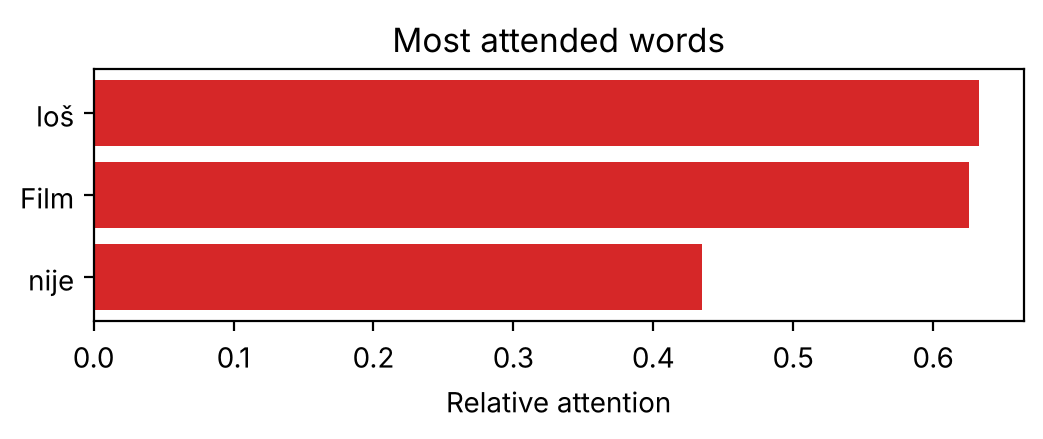

**Specijalni efekti su impresivni, ali scenario je toliko slab da ni gluma ne može da ga spase.** → p(positive) = 0.10

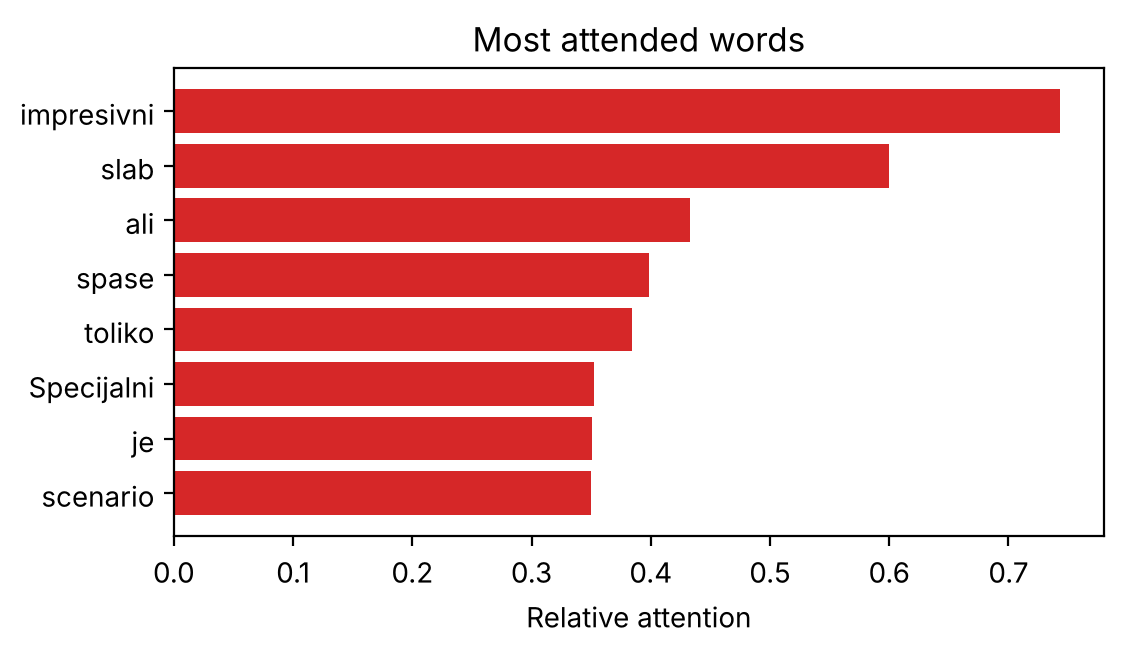

In [8]:
from sentiment.models.transformer import TransformerPredictor

source = (
    "artifacts/bertic/model"
    if Path("artifacts/bertic/model").exists()
    else "aleksbrstina/bertic-serbmr-sentiment"
)
bertic = TransformerPredictor.load(source)


def show_attention(text: str, top_k: int = 12) -> None:
    pairs = bertic.word_attention(text)
    spans = []
    for word, weight in pairs:
        if weight is None:
            spans.append("<b> […] </b>")
        else:
            spans.append(
                f'<span style="background: rgba(214,39,40,{weight:.2f}); padding: 1px 2px">{word}</span>'
            )
    display(HTML('<div style="line-height: 1.9; font-size: 13px">' + " ".join(spans) + "</div>"))
    ranked = sorted((p for p in pairs if p[1] is not None and p[0].isalpha()), key=lambda p: -p[1])[
        :top_k
    ]
    fig, ax = plt.subplots(figsize=(6, 0.28 * len(ranked) + 0.8))
    ax.barh([w for w, _ in ranked][::-1], [v for _, v in ranked][::-1], color="#d62728")
    ax.set(xlabel="Relative attention", title="Most attended words")
    plt.show()


for sentence in [
    "Film nije loš.",
    "Specijalni efekti su impresivni, ali scenario je toliko slab da ni gluma ne može da ga spase.",
]:
    p = bertic.predict_proba([sentence])[0]
    display(Markdown(f"**{sentence}** → p(positive) = {p[bertic.labels.index('positive')]:.2f}"))
    show_attention(sentence, top_k=8)

**Test review 1186** (gold *negative*, BERTić correct, TF-IDF wrong)

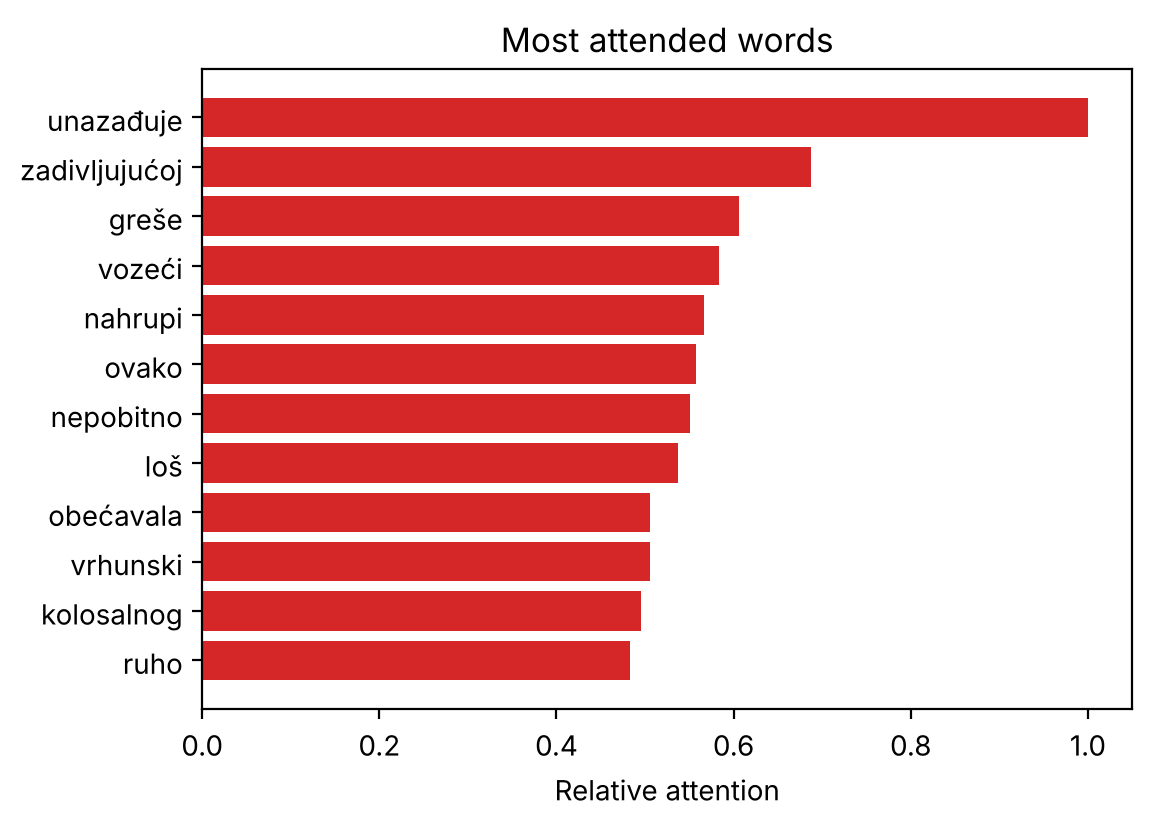

In [9]:
rid = 1186
display(
    Markdown(
        f"**Test review {rid}** (gold *{pred.set_index('id').loc[rid, 'label']}*, BERTić correct, TF-IDF wrong)"
    )
)
show_attention(test.loc[rid, "text"])

## 6. Takeaways
Generated from the tables above.

In [10]:
best = summary["macro_f1"].idxmax()
lr_vs = pairwise.set_index("model").loc[NAMES["logreg"]]
contra = rates[rates["tag"] == "contradicting_cues"].set_index("model")["error_tagged"]
from sentiment.models.neural.tokenizer import tokenize

mean_tokens = test["text"].map(lambda t: len(tokenize(t))).mean()
long_tag = rates[rates["tag"] == "long"].set_index("model")["error_tagged"]
display(
    Markdown(
        "\n".join(
            [
                f"1. **{NAMES[best]}** is the best model (macro F1 {summary.loc[best, 'macro_f1']:.3f}, 95% CI "
                f"{summary.loc[best, 'ci_low']:.3f}–{summary.loc[best, 'ci_high']:.3f}); its lead over TF-IDF + LR "
                f"(+{lr_vs['diff']:.3f}, CI {lr_vs['diff_low']:+.3f} to {lr_vs['diff_high']:+.3f}, McNemar p = {lr_vs['mcnemar_p']:.3f}) "
                "is statistically reliable.",
                f"2. **Contradicting cues** (mixed sentiment) are the main weakness of bag-of-words: error rate "
                f"{contra[NAMES['logreg']]:.0%} for TF-IDF + LR vs. {contra[NAMES['bertic']]:.0%} for BERTić.",
                f"3. **Long reviews** hurt the BiLSTM most ({long_tag[NAMES['bilstm']]:.0%} errors), consistent with it seeing "
                f"only 256 of {mean_tokens:.0f} tokens on average.",
                f"4. The cost: BERTić needs {summary.loc[best, 'latency_ms_single']:.0f} ms per review on CPU and "
                f"{summary.loc[best, 'size_mb']:.0f} MB, vs. {summary.loc['logreg', 'latency_ms_single']:.0f} ms and "
                f"{summary.loc['logreg', 'size_mb']:.1f} MB for TF-IDF + LR.",
            ]
        )
    )
)

1. **BERTić** is the best model (macro F1 0.917, 95% CI 0.874–0.958); its lead over TF-IDF + LR (+0.083, CI +0.015 to +0.149, McNemar p = 0.024) is statistically reliable.
2. **Contradicting cues** (mixed sentiment) are the main weakness of bag-of-words: error rate 42% for TF-IDF + LR vs. 14% for BERTić.
3. **Long reviews** hurt the BiLSTM most (42% errors), consistent with it seeing only 256 of 470 tokens on average.
4. The cost: BERTić needs 99 ms per review on CPU and 443 MB, vs. 4 ms and 1.5 MB for TF-IDF + LR.